---
# <font color="#CA3532">Deep Learning Fundamentals and Basic Tools (2026/2027) - Final project</font>
---


In this project you will implement and compare four deep-learning architectures for multiclass human activity recognition:

- Deep Neural Network (DNN)
- Recurrent Neural Network (RNN)
- 1D Convolutional Neural Network (CNN)
- Long Short-Term Memory Network (LSTM)

You will work with the **UCI Human Activity Recognition Using Smartphones (UCI HAR)** dataset.

You must compare predictive performance, class-level errors, convergence, model complexity, training time, inference time, and stability across repeated runs.

## <font color="#3279ca">Generative-AI Policy</font>


The use of any generative-AI or Large Language Model (LLM) to generate, complete, rewrite, or substantially assist with the code, experiments, analysis, or written answers for this project is **not permitted**.

**Work generated using LLM assistance will be treated as plagiarism. If it is the case, the corresponding project code will not be evaluated and the student will receive no credit for that work.**


## <font color="#3279ca">Project report</font>

You must write a project report explaning the following points;

- individual functions and model layers;
- tensor dimensions;
- the training procedure;
- suugest an alternative for part of your implementation;
- interpret results, confusion matrices, and all metrics;
- explain your conclusions.

Do not submit code or analysis that you cannot explain.

### <font color="#0da432">Imports</font>

In [37]:

import json
import sys
import importlib
from pathlib import Path
from sklearn.model_selection import GroupShuffleSplit

if "src.models" in sys.modules:
    del sys.modules["src.models"]

import src.models
importlib.reload(src.models)
import time
import platform
from src.utils import set_seed
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder, StandardScaler

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

import torch
from src.models import (
    DNNClassifier,
    RNNClassifier,
    CNNClassifier,
    LSTMClassifier,
)
from src.training import fit
from src.evaluation import (
    evaluate_model,
    count_parameters,
    measure_inference_time,
)

### <font color="#0da432">Dataset</font>

In [38]:
train_df = pd.read_csv("../data/final_project/train.csv")
test_df = pd.read_csv("../data/final_project/test.csv")

TARGET = "Activity"
DROP_COLUMNS = ["subject", TARGET]

X = train_df.drop(columns=DROP_COLUMNS).to_numpy(dtype=np.float32)
X_test = test_df.drop(columns=DROP_COLUMNS).to_numpy(dtype=np.float32)

label_encoder = LabelEncoder()

y = label_encoder.fit_transform(train_df[TARGET]).astype(np.int64)
y_test = label_encoder.transform(test_df[TARGET]).astype(np.int64)

class_names = label_encoder.classes_

# Create validation split from training data
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, val_idx = next(
    splitter.split(X, y, groups=train_df["subject"])
)

X_train = X[train_idx]
X_val = X[val_idx]

y_train = y[train_idx]
y_val = y[val_idx]

# Verify subjects do not overlap
train_subjects = set(train_df.iloc[train_idx]["subject"])
val_subjects = set(train_df.iloc[val_idx]["subject"])

assert train_subjects.isdisjoint(val_subjects), \
    "Subject leakage detected!"

# Scale using ONLY training data
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train).astype(np.float32)
X_val = scaler.transform(X_val).astype(np.float32)
X_test = scaler.transform(X_test).astype(np.float32)

# Dataset dimensions
n_features = X_train.shape[1]
n_classes = len(class_names)

sequence_length = n_features

# DNN
X_train_dnn = X_train
X_val_dnn = X_val
X_test_dnn = X_test

# RNN / LSTM
# Shape: (samples, sequence_length, features_per_step)
X_train_rnn = X_train[..., np.newaxis]
X_val_rnn = X_val[..., np.newaxis]
X_test_rnn = X_test[..., np.newaxis]

X_train_lstm = X_train[..., np.newaxis]
X_val_lstm = X_val[..., np.newaxis]
X_test_lstm = X_test[..., np.newaxis]

# CNN - TensorFlow / Keras Conv1D
# Shape: (samples, length, channels)
X_train_cnn_tf = X_train[..., np.newaxis]
X_val_cnn_tf = X_val[..., np.newaxis]
X_test_cnn_tf = X_test[..., np.newaxis]

# CNN - PyTorch Conv1d
# Shape: (samples, channels, length)
X_train_cnn_torch = X_train[:, np.newaxis, :]
X_val_cnn_torch = X_val[:, np.newaxis, :]
X_test_cnn_torch = X_test[:, np.newaxis, :]

# Display dataset information
print("Training shape:", X_train.shape)
print("Validation shape:", X_val.shape)
print("Test shape:", X_test.shape)

print("Number of features:", n_features)
print("Number of classes:", n_classes)

print("Training subjects:", len(train_subjects))
print("Validation subjects:", len(val_subjects))
print("Subject overlap:", len(train_subjects & val_subjects))


Training shape: (5551, 561)
Validation shape: (1801, 561)
Test shape: (2947, 561)
Number of features: 561
Number of classes: 6
Training subjects: 16
Validation subjects: 5
Subject overlap: 0


## <font color="#0da432">Implementation Requirements</font>
rgb(18, 13, 164)
You must implement the backend yourself.

Required files:

```text
src/models.py
src/training.py
src/evaluation.py
```

## `src/models.py`

Implement:

```python
DNNClassifier
RNNClassifier
CNNClassifier
LSTMClassifier
```

All models receive the same underlying information and must ultimately output:

```text
(batch_size, 6)
```

logits/scores.

### DNN

Transform:

```text
(batch, 561)
```

into an appropriate vector representation.

### RNN

Process the engineered feature positions sequentially with a vanilla recurrent architecture.

### CNN

Use one-dimensional convolution over the temporal dimension.

### LSTM

Use an LSTM-based sequence representation for classification.

Important architectural parameters should be configurable.

##  `src/training.py`

Implement:

```python
fit(
    model,
    X_train,
    y_train,
    X_val,
    y_val,
    **kwargs
)
```

It must return at least:

```python
{
    "model": ...,
    "history": {
        "train_loss": ...,
        "val_loss": ...,
        "train_accuracy": ...,
        "val_accuracy": ...
    },
    "training_time": ...,
    "epochs_completed": ...
}
```

Support appropriate training settings including epochs, batch size, learning rate, seed, device, and early stopping.

##  `src/evaluation.py`

Implement:

```python
evaluate_model(model, X, y, **kwargs)
count_parameters(model)
measure_inference_time(model, X, **kwargs)
```

`evaluate_model` must return at least:

```python
{
    "accuracy": ...,
    "macro_precision": ...,
    "macro_recall": ...,
    "macro_f1": ...,
    "weighted_f1": ...,
    "predictions": ...
}
```

##  `src/utils.py`

Implement:

```python
set_seed(seed)
```

The function must set the relevant random seeds for reproducibility.

# Instantiate DNN, RNN, CNN and LSTM

You may add additional keyword arguments supported by your implementation.

Document your final architecture choices.

In [ ]:
SEED = 42
set_seed(SEED)

dnn_model = DNNClassifier(
    sequence_length=sequence_length,
    n_features=n_features,
    n_classes=n_classes,
)

rnn_model = RNNClassifier(
    input_size=n_features,
    n_classes=n_classes,
)

cnn_model = CNNClassifier(
    input_size=n_features,
    n_classes=n_classes,
)

lstm_model = LSTMClassifier(
    input_size=n_features,
    n_classes=n_classes,
)

models = {
    "DNN": dnn_model,
    "RNN": rnn_model,
    "CNN": cnn_model,
    "LSTM": lstm_model,
}

# Forward-Pass

In [ ]:
sample_batch = torch.tensor(
    X_train[:8],
    dtype=torch.float32,
)

for name, model in models.items():
    model.eval()

    with torch.no_grad():
        output = model(sample_batch)

    print(
        f"{name:5s} | "
        f"input={tuple(sample_batch.shape)} | "
        f"output={tuple(output.shape)}"
    )

    assert output.shape == (8, n_classes)

DNN   | input=(8, 561) | output=(8, 6)
RNN   | input=(8, 561) | output=(8, 6)
CNN   | input=(8, 561) | output=(8, 6)
LSTM  | input=(8, 561) | output=(8, 6)


### Architecture documentation

For each architecture document:

- input representation;
- layer structure;
- hidden/filter dimensions;
- activation functions;
- dropout;
- output representation;
- parameter choices;
- what temporal information the architecture can exploit.

**TODO:** Write your architecture documentation in the project report.

# Training

Use comparable conditions.

Do not use the test set for model selection or hyperparameter tuning.

In [ ]:
TRAINING_CONFIG = {
    "epochs": 50,
    "batch_size": 64,
    "learning_rate": 1e-3,
    "patience": 8,
    "seed": SEED,
}

TRAINING_CONFIG

{'epochs': 50,
 'batch_size': 64,
 'learning_rate': 0.001,
 'patience': 8,
 'seed': 42}

# Train DNN

In [ ]:
dnn_result = fit(
    dnn_model,
    X_train, y_train,
    X_val, y_val,
    **TRAINING_CONFIG,
)

dnn_model = dnn_result["model"]

print("Training time:", dnn_result["training_time"])
print("Epochs:", dnn_result["epochs_completed"])

AcceleratorError: CUDA error: unspecified launch failure
Search for `cudaErrorLaunchFailure' in https://docs.nvidia.com/cuda/cuda-runtime-api/group__CUDART__TYPES.html for more information.
CUDA kernel errors might be asynchronously reported at some other API call, so the stacktrace below might be incorrect.
For debugging consider passing CUDA_LAUNCH_BLOCKING=1
The CUDA driver logged these messages, which may provide useful details:
Returning 719 (CUDA_ERROR_LAUNCH_FAILED) from cuStreamSynchronize



# Train RNN

In [ ]:
rnn_result = fit(
    rnn_model,
    X_train, y_train,
    X_val, y_val,
    **TRAINING_CONFIG,
)

rnn_model = rnn_result["model"]

print("Training time:", rnn_result["training_time"])
print("Epochs:", rnn_result["epochs_completed"])

Epoch   1/50 | train loss 1.3923 acc 0.4543 | val loss 0.9938 acc 0.6163 | 0.85s *
Epoch   2/50 | train loss 0.8521 acc 0.6275 | val loss 0.7654 acc 0.6902 | 0.79s *
Epoch   3/50 | train loss 0.7562 acc 0.6687 | val loss 0.7357 acc 0.7240 | 0.78s *
Epoch   4/50 | train loss 0.7036 acc 0.6943 | val loss 0.6667 acc 0.7846 | 0.78s *
Epoch   5/50 | train loss 0.6268 acc 0.7206 | val loss 0.6548 acc 0.7873 | 0.79s *
Epoch   6/50 | train loss 0.5906 acc 0.7364 | val loss 0.4972 acc 0.7951 | 0.79s *
Epoch   7/50 | train loss 0.6469 acc 0.7285 | val loss 0.6559 acc 0.7579 | 0.80s
Epoch   8/50 | train loss 0.5799 acc 0.7418 | val loss 0.6540 acc 0.7773 | 0.80s
Epoch   9/50 | train loss 0.5500 acc 0.7563 | val loss 0.5909 acc 0.7940 | 0.80s
Epoch  10/50 | train loss 0.5205 acc 0.7662 | val loss 0.4136 acc 0.8190 | 0.80s *
Epoch  11/50 | train loss 0.5013 acc 0.7763 | val loss 0.4385 acc 0.8173 | 0.80s
Epoch  12/50 | train loss 0.5251 acc 0.7730 | val loss 0.7078 acc 0.7907 | 0.79s
Epoch  13/50 |

# Train CNN

In [ ]:
cnn_result = fit(
    cnn_model,
    X_train, y_train,
    X_val, y_val,
    **TRAINING_CONFIG,
)

cnn_model = cnn_result["model"]

print("Training time:", cnn_result["training_time"])
print("Epochs:", cnn_result["epochs_completed"])

Epoch   1/50 | train loss 1.0146 acc 0.5527 | val loss 0.8740 acc 0.6258 | 2.96s *
Epoch   2/50 | train loss 0.7428 acc 0.6774 | val loss 0.7055 acc 0.7202 | 2.36s *
Epoch   3/50 | train loss 0.6103 acc 0.7422 | val loss 0.8293 acc 0.5825 | 2.37s
Epoch   4/50 | train loss 0.5145 acc 0.7894 | val loss 0.7092 acc 0.6541 | 2.38s
Epoch   5/50 | train loss 0.4777 acc 0.8090 | val loss 0.5475 acc 0.7446 | 2.40s *
Epoch   6/50 | train loss 0.4140 acc 0.8299 | val loss 0.5030 acc 0.7801 | 2.40s *
Epoch   7/50 | train loss 0.3819 acc 0.8508 | val loss 0.5285 acc 0.7457 | 2.34s
Epoch   8/50 | train loss 0.3626 acc 0.8616 | val loss 0.9519 acc 0.7235 | 2.35s
Epoch   9/50 | train loss 0.3268 acc 0.8771 | val loss 1.7149 acc 0.4870 | 2.33s
Epoch  10/50 | train loss 0.3037 acc 0.8878 | val loss 1.5035 acc 0.5130 | 2.37s
Epoch  11/50 | train loss 0.2799 acc 0.8993 | val loss 1.1609 acc 0.5580 | 2.42s
Epoch  12/50 | train loss 0.2773 acc 0.8973 | val loss 0.3591 acc 0.8318 | 2.39s *
Epoch  13/50 | tra

# Train LSTM

In [ ]:
lstm_result = fit(
    lstm_model,
    X_train, y_train,
    X_val, y_val,
    **TRAINING_CONFIG,
)

lstm_model = lstm_result["model"]

print("Training time:", lstm_result["training_time"])
print("Epochs:", lstm_result["epochs_completed"])

Epoch   1/50 | train loss 1.5559 acc 0.3428 | val loss 1.1927 acc 0.5441 | 2.04s *
Epoch   2/50 | train loss 0.9589 acc 0.5549 | val loss 0.8565 acc 0.6219 | 2.08s *
Epoch   3/50 | train loss 0.7953 acc 0.6001 | val loss 0.8061 acc 0.6469 | 2.09s *
Epoch   4/50 | train loss 0.7152 acc 0.6577 | val loss 0.6859 acc 0.7224 | 2.10s *
Epoch   5/50 | train loss 0.6436 acc 0.6946 | val loss 0.6027 acc 0.7413 | 2.11s *
Epoch   6/50 | train loss 0.6032 acc 0.7173 | val loss 0.6318 acc 0.7635 | 2.10s
Epoch   7/50 | train loss 0.6067 acc 0.7094 | val loss 0.5584 acc 0.7746 | 2.10s *
Epoch   8/50 | train loss 0.5730 acc 0.7330 | val loss 0.5615 acc 0.8051 | 2.12s
Epoch   9/50 | train loss 0.5589 acc 0.7395 | val loss 0.4966 acc 0.7662 | 2.13s *
Epoch  10/50 | train loss 0.5531 acc 0.7478 | val loss 0.6446 acc 0.7468 | 2.11s
Epoch  11/50 | train loss 0.5584 acc 0.7545 | val loss 0.5004 acc 0.7812 | 2.13s
Epoch  12/50 | train loss 0.5314 acc 0.7582 | val loss 0.5038 acc 0.8101 | 2.13s
Epoch  13/50 |

# Collect Training Results

In [ ]:
training_results = {
    "DNN": dnn_result,
    "RNN": rnn_result,
    "CNN": cnn_result,
    "LSTM": lstm_result,
}

trained_models = {
    name: result["model"]
    for name, result in training_results.items()
}

# Loss Curves

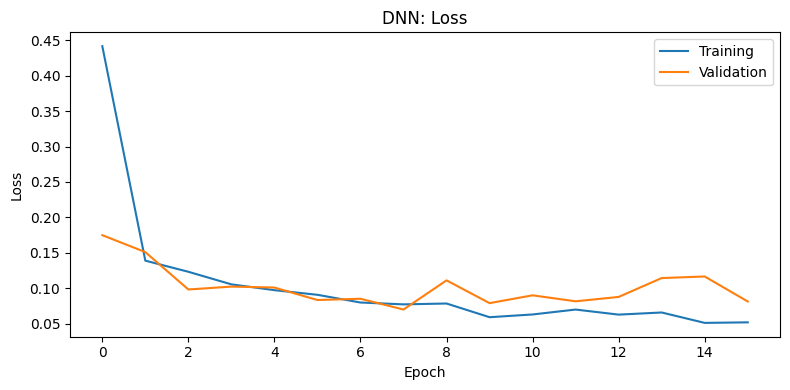

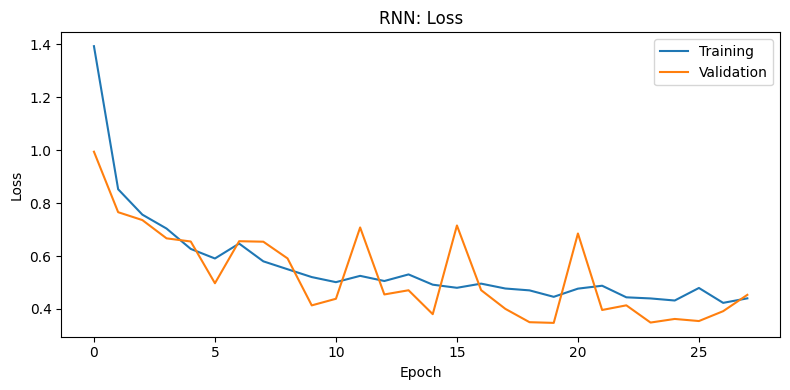

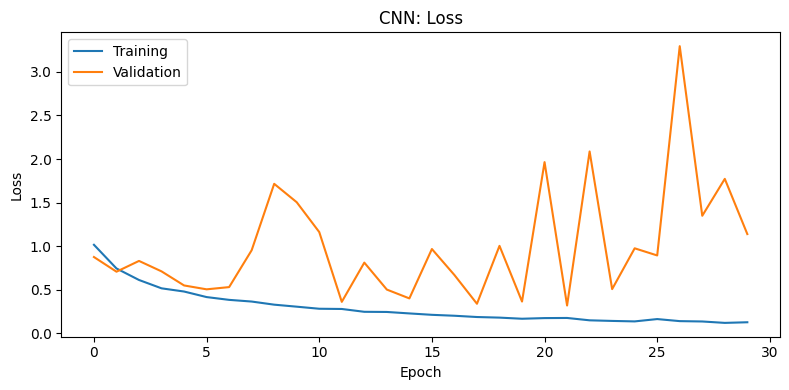

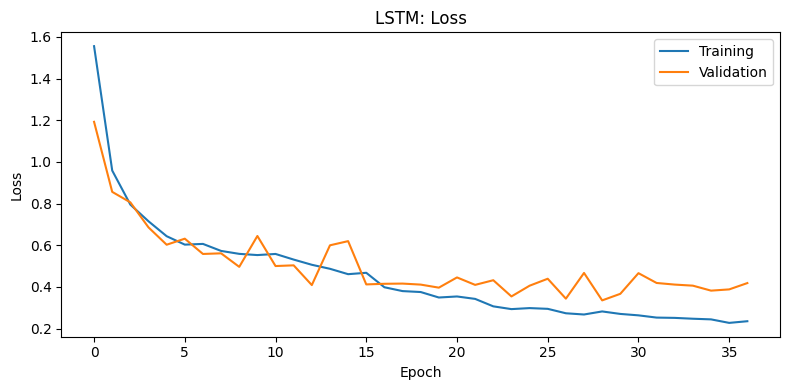

In [ ]:
for name, result in training_results.items():
    history = result["history"]

    plt.figure(figsize=(8, 4))
    plt.plot(history["train_loss"], label="Training")
    plt.plot(history["val_loss"], label="Validation")
    plt.title(f"{name}: Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.tight_layout()
    plt.show()

#  Accuracy Curves

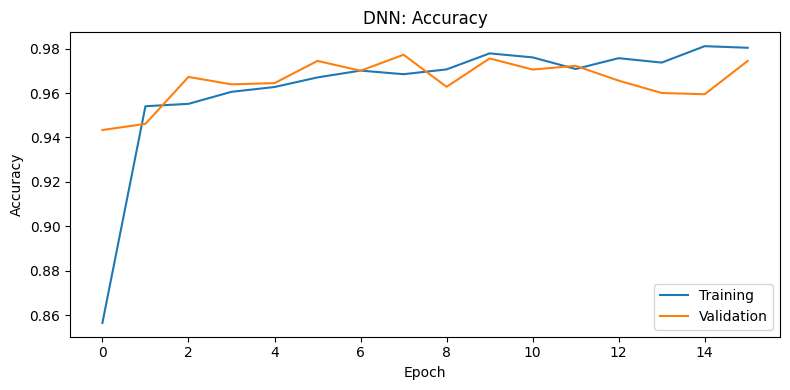

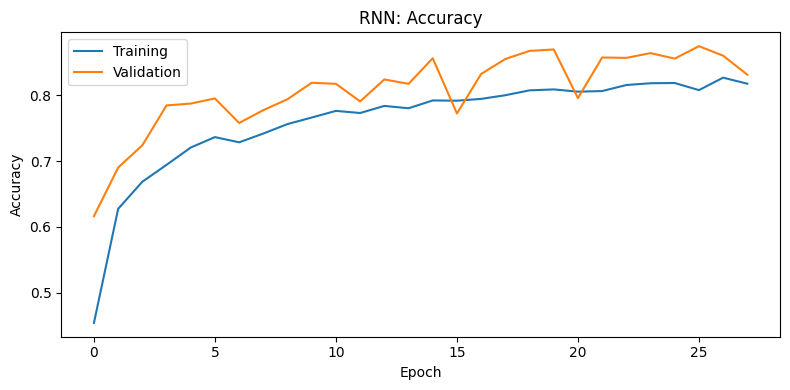

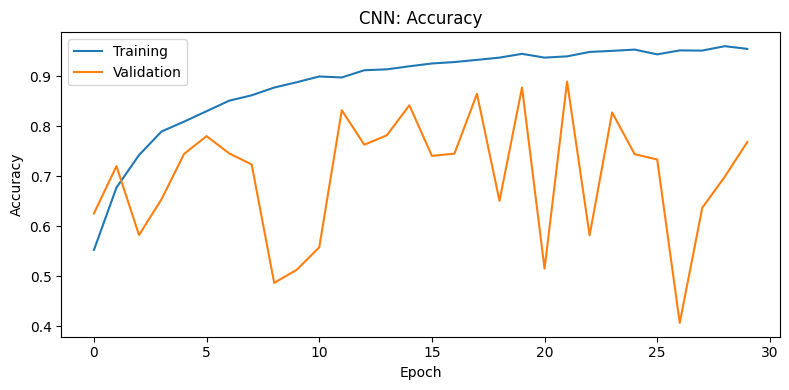

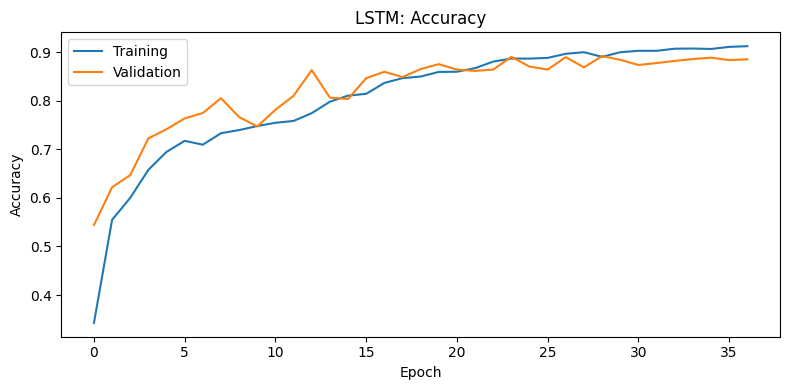

In [ ]:
for name, result in training_results.items():
    history = result["history"]

    plt.figure(figsize=(8, 4))
    plt.plot(history["train_accuracy"], label="Training")
    plt.plot(history["val_accuracy"], label="Validation")
    plt.title(f"{name}: Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.tight_layout()
    plt.show()

### Training behavior analysis

For each architecture explain:

- convergence speed;
- overfitting;
- underfitting;
- stability;
- early stopping;
- train/validation gap.

**TODO:** Write add your analysis in ypur report.

# Final Test Evaluation



Report:

- Accuracy
- Macro Precision
- Macro Recall
- Macro F1
- Weighted F1
- Per-class metrics

In [ ]:
test_results = {}

for name, model in trained_models.items():
    test_results[name] = evaluate_model(
        model,
        X_test,
        y_test,
    )

comparison_df = pd.DataFrame([
    {
        "Model": name,
        "Accuracy": result["accuracy"],
        "Macro Precision": result["macro_precision"],
        "Macro Recall": result["macro_recall"],
        "Macro F1": result["macro_f1"],
        "Weighted F1": result["weighted_f1"],
    }
    for name, result in test_results.items()
])

comparison_df

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1
0,DNN,0.941636,0.946511,0.940391,0.941866,0.941742
1,RNN,0.752630,0.748649,0.743422,0.744951,0.754794
2,CNN,0.895148,0.901856,0.893273,0.892226,0.894217
3,LSTM,0.819817,0.825151,0.813400,0.815065,0.819099


# Per-Class Classification Reports

In [ ]:
for name, result in test_results.items():
    print("\n" + "=" * 80)
    print(name)
    print("=" * 80)

    print(
        classification_report(
            y_test,
            result["predictions"],
            target_names=class_names,
            digits=4,
        )
    )


DNN
                    precision    recall  f1-score   support

            LAYING     1.0000    0.9777    0.9887       537
           SITTING     0.9592    0.8615    0.9077       491
          STANDING     0.8624    0.9662    0.9113       532
           WALKING     0.9046    0.9940    0.9472       496
WALKING_DOWNSTAIRS     0.9826    0.9429    0.9623       420
  WALKING_UPSTAIRS     0.9703    0.9002    0.9339       471

          accuracy                         0.9416      2947
         macro avg     0.9465    0.9404    0.9419      2947
      weighted avg     0.9451    0.9416    0.9417      2947


RNN
                    precision    recall  f1-score   support

            LAYING     1.0000    0.9479    0.9732       537
           SITTING     0.8517    0.7719    0.8098       491
          STANDING     0.8003    0.8741    0.8356       532
           WALKING     0.6377    0.6210    0.6292       496
WALKING_DOWNSTAIRS     0.5180    0.5833    0.5487       420
  WALKING_UPSTAIRS     0.6

# Confusion Matrices

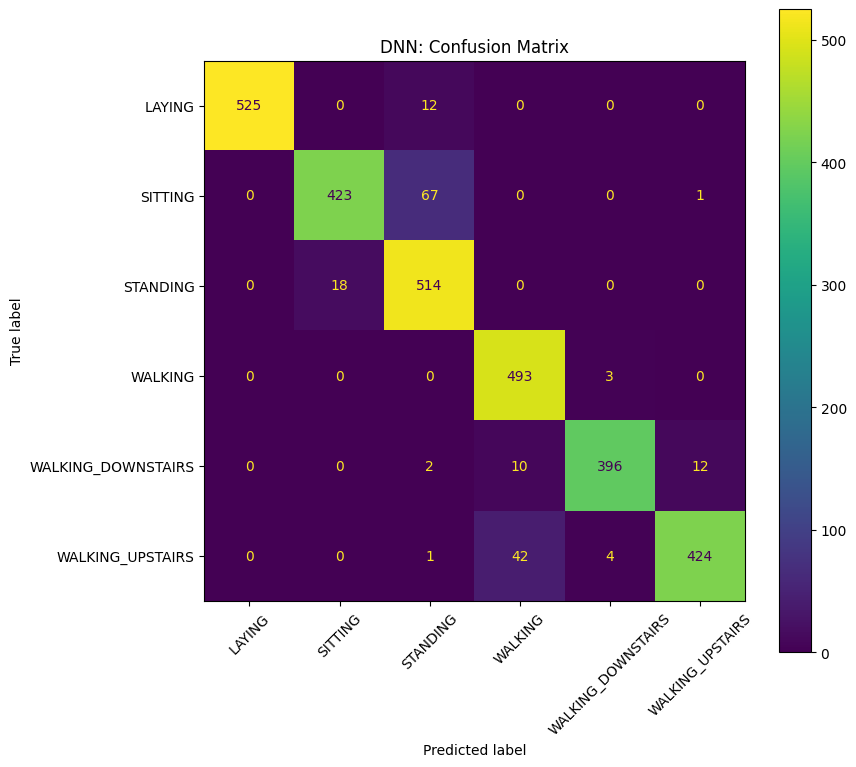

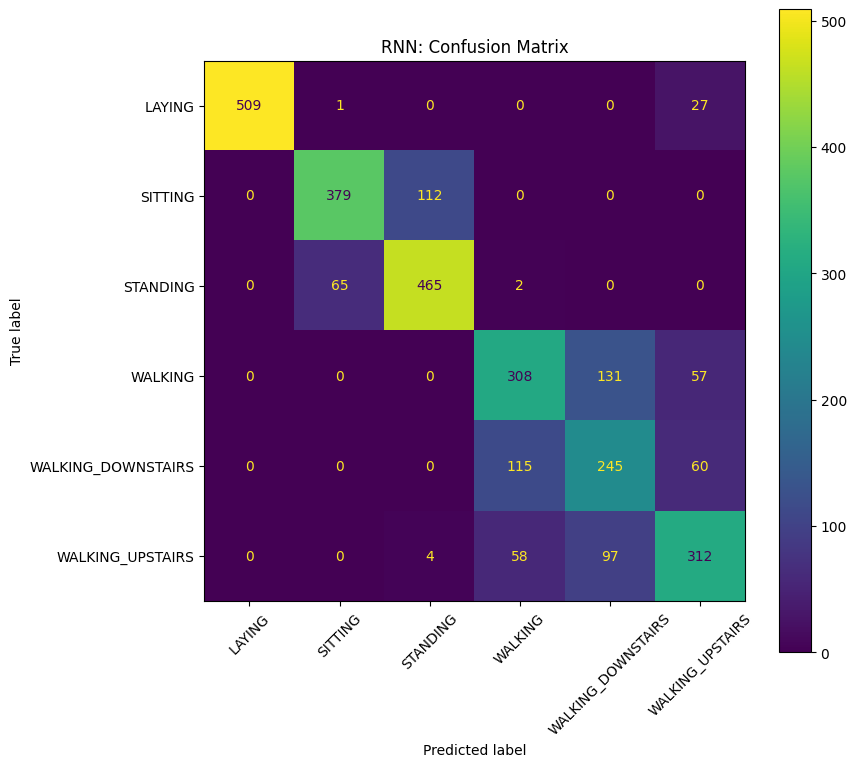

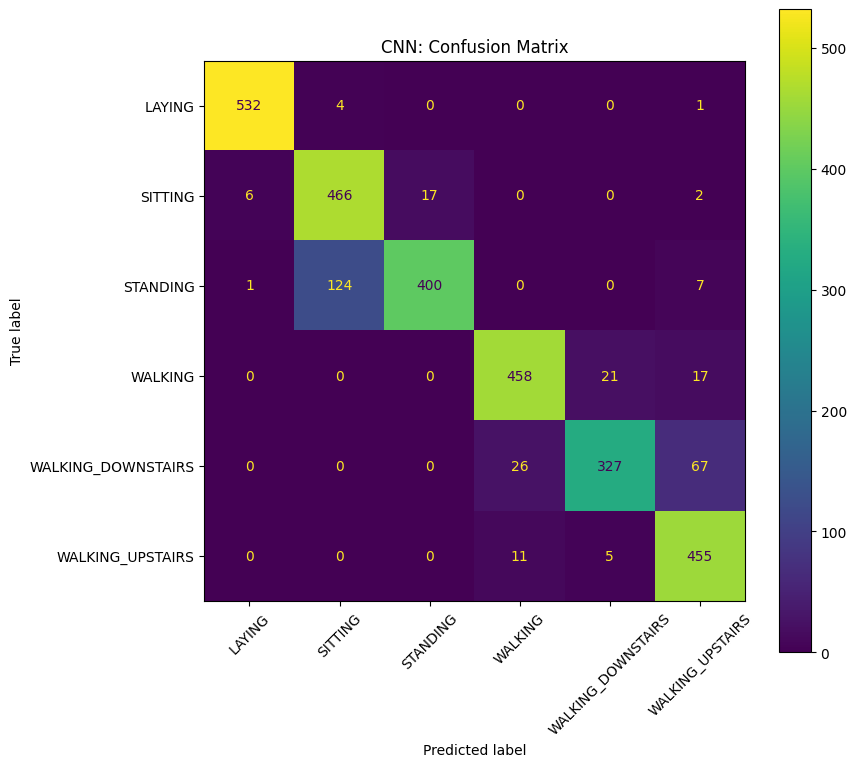

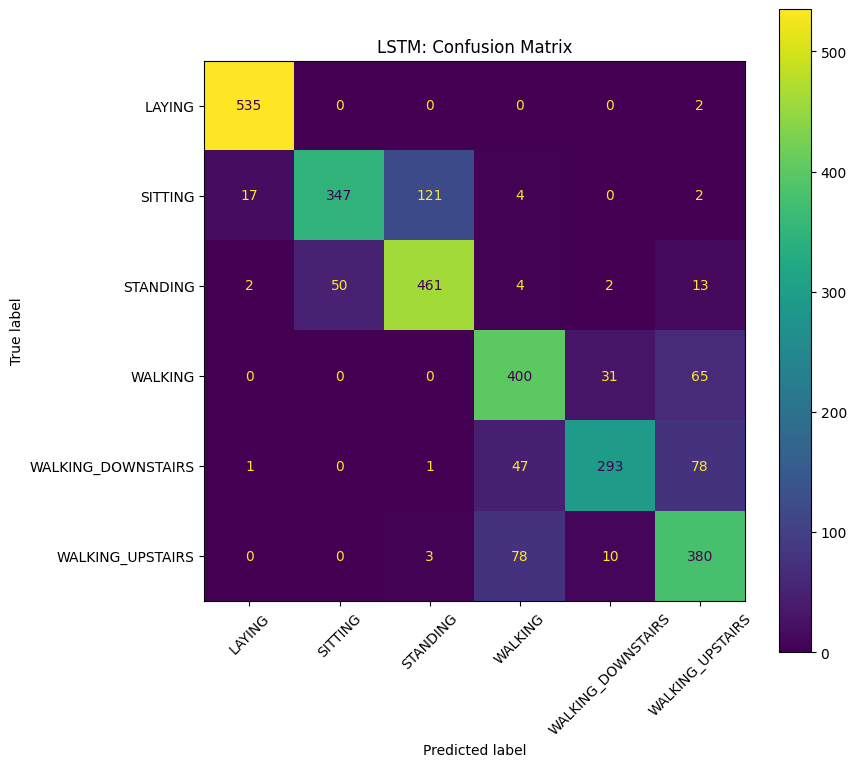

In [ ]:
for name, result in test_results.items():
    cm = confusion_matrix(
        y_test,
        result["predictions"],
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=class_names,
    )

    fig, ax = plt.subplots(figsize=(9, 8))
    disp.plot(ax=ax, xticks_rotation=45)
    plt.title(f"{name}: Confusion Matrix")
    plt.tight_layout()
    plt.show()

### Activity-specific error analysis

Explain in ypur report:

- whether recurrent models make similar errors.
- whether CNN differs from RNN/LSTM.
- whether flattening disadvantages the DNN.


# Trainable Parameter Counts

In [ ]:
parameter_counts = {
    name: count_parameters(model)
    for name, model in trained_models.items()
}

parameter_df = pd.DataFrame({
    "Model": list(parameter_counts.keys()),
    "Parameters": list(parameter_counts.values()),
})

parameter_df

,Model,Parameters
0,DNN,178310
1,RNN,4678
2,CNN,52806
3,LSTM,17542


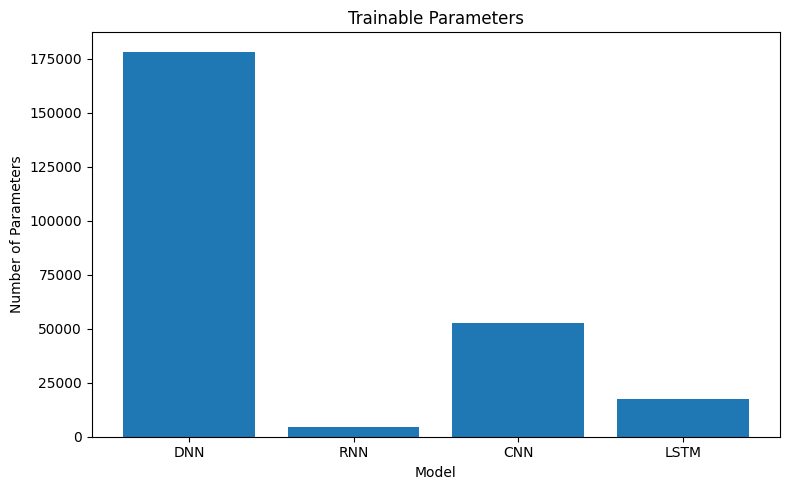

In [ ]:
plt.figure(figsize=(8, 5))
plt.bar(parameter_df["Model"], parameter_df["Parameters"])
plt.title("Trainable Parameters")
plt.xlabel("Model")
plt.ylabel("Number of Parameters")
plt.tight_layout()
plt.show()

# Training-Time Comparison

In [ ]:
training_time_df = pd.DataFrame([
    {
        "Model": name,
        "Training Time": result["training_time"],
        "Epochs": result["epochs_completed"],
        "Average Time / Epoch": (
            result["training_time"] /
            max(result["epochs_completed"], 1)
        ),
    }
    for name, result in training_results.items()
])

training_time_df

,Model,Training Time,Epochs,Average Time / Epoch
0,DNN,6.585700,16,0.411606
1,RNN,22.226215,28,0.793793
2,CNN,71.647692,30,2.388256
3,LSTM,79.369207,37,2.145114


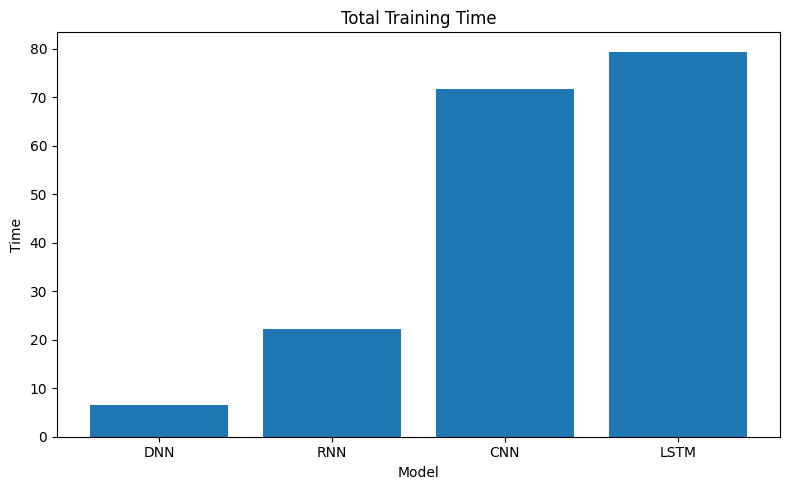

In [ ]:
plt.figure(figsize=(8, 5))
plt.bar(
    training_time_df["Model"],
    training_time_df["Training Time"],
)
plt.title("Total Training Time")
plt.xlabel("Model")
plt.ylabel("Time")
plt.tight_layout()
plt.show()

# Inference-Time Comparison

In [ ]:
inference_times = {
    name: measure_inference_time(model, X_test)
    for name, model in trained_models.items()
}

inference_df = pd.DataFrame({
    "Model": list(inference_times.keys()),
    "Inference Time": list(inference_times.values()),
})

inference_df

,Model,Inference Time
0,DNN,0.003624
1,RNN,0.111761
2,CNN,0.455242
3,LSTM,0.281366


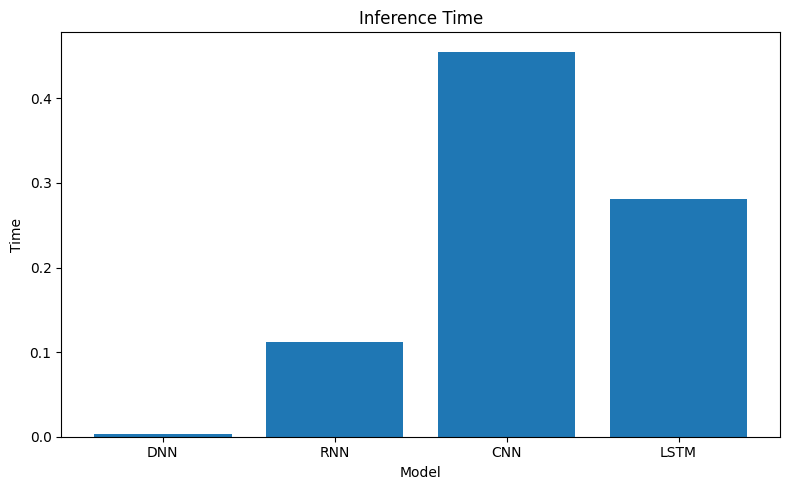

In [ ]:
plt.figure(figsize=(8, 5))
plt.bar(
    inference_df["Model"],
    inference_df["Inference Time"],
)
plt.title("Inference Time")
plt.xlabel("Model")
plt.ylabel("Time")
plt.tight_layout()
plt.show()

# Complete Model Comparison

In [ ]:
final_comparison = comparison_df.copy()

final_comparison["Parameters"] = (
    final_comparison["Model"].map(parameter_counts)
)

final_comparison["Training Time"] = (
    final_comparison["Model"].map({
        name: result["training_time"]
        for name, result in training_results.items()
    })
)

final_comparison["Inference Time"] = (
    final_comparison["Model"].map(inference_times)
)

final_comparison

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,Parameters,Training Time,Inference Time
0,DNN,0.941636,0.946511,0.940391,0.941866,0.941742,178310,6.585700,0.003624
1,RNN,0.752630,0.748649,0.743422,0.744951,0.754794,4678,22.226215,0.111761
2,CNN,0.895148,0.901856,0.893273,0.892226,0.894217,52806,71.647692,0.455242
3,LSTM,0.819817,0.825151,0.813400,0.815065,0.819099,17542,79.369207,0.281366


# Predictive-Metric Comparison

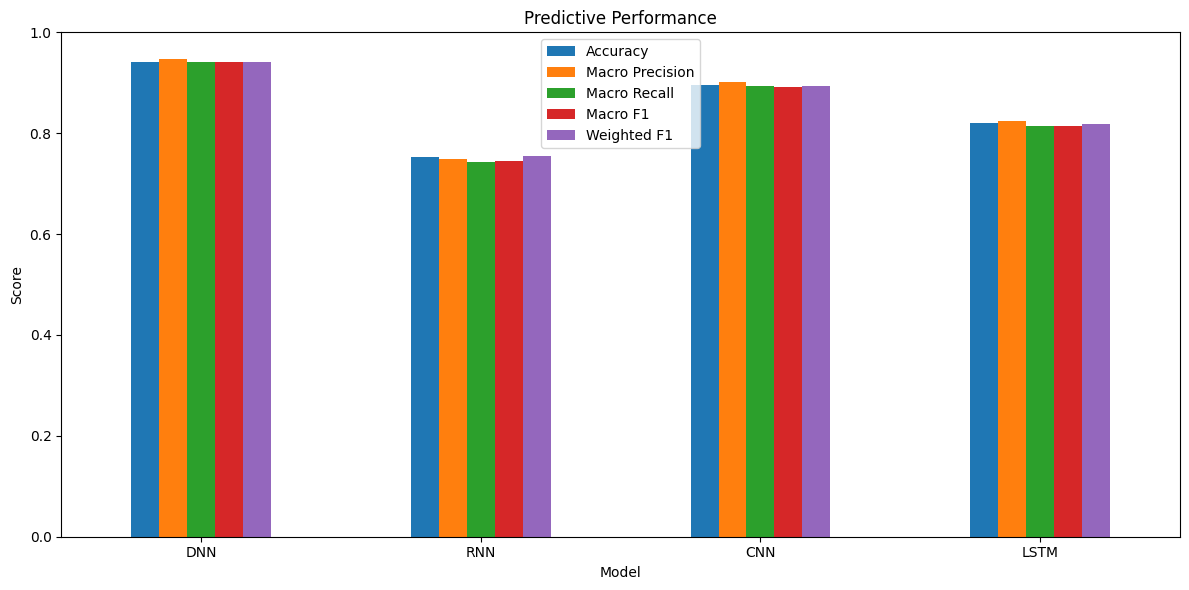

In [ ]:
metric_columns = [
    "Accuracy",
    "Macro Precision",
    "Macro Recall",
    "Macro F1",
    "Weighted F1",
]

final_comparison.set_index("Model")[metric_columns].plot(
    kind="bar",
    figsize=(12, 6),
)

plt.title("Predictive Performance")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Performance vs Computational Cost

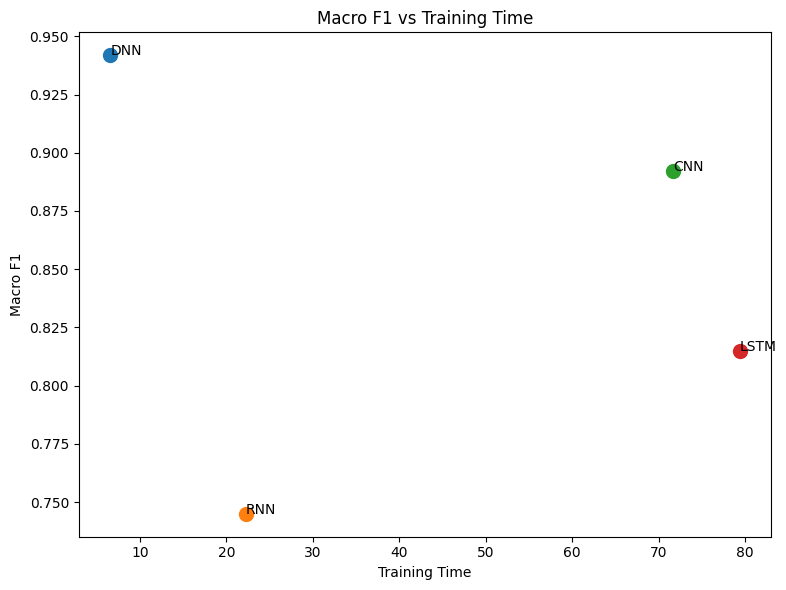

In [ ]:
plt.figure(figsize=(8, 6))

for _, row in final_comparison.iterrows():
    plt.scatter(
        row["Training Time"],
        row["Macro F1"],
        s=100,
    )
    plt.annotate(
        row["Model"],
        (row["Training Time"], row["Macro F1"]),
    )

plt.xlabel("Training Time")
plt.ylabel("Macro F1")
plt.title("Macro F1 vs Training Time")
plt.tight_layout()
plt.show()

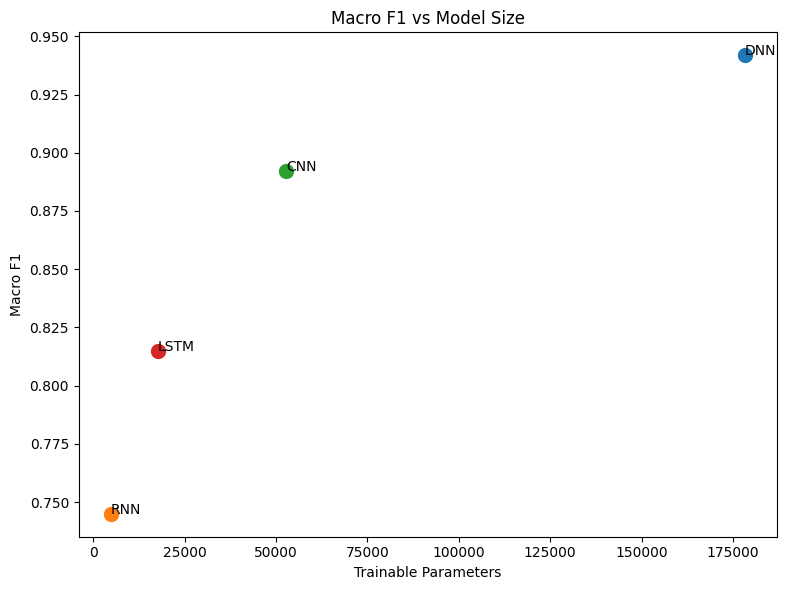

In [ ]:
plt.figure(figsize=(8, 6))

for _, row in final_comparison.iterrows():
    plt.scatter(
        row["Parameters"],
        row["Macro F1"],
        s=100,
    )
    plt.annotate(
        row["Model"],
        (row["Parameters"], row["Macro F1"]),
    )

plt.xlabel("Trainable Parameters")
plt.ylabel("Macro F1")
plt.title("Macro F1 vs Model Size")
plt.tight_layout()
plt.show()

### Performance/cost discussion

Does increased architectural complexity produce a meaningful performance improvement relative to its computational cost?

**TODO:** Add your analysis in your report.

# Repeated Experiments: Three Random Seeds

Run the main comparison with at least:

```python
SEEDS = [1, 42, 123]
```

Instantiate a **new model** for every run.

Do not reuse previously trained weights.

In [ ]:
SEEDS = [1, 42, 123]

seed_experiment_results = []

# TODO:
#
# for seed in SEEDS:
#     1. set_seed(seed)
#     2. instantiate fresh DNN/RNN/CNN/LSTM objects
#     3. train each model
#     4. evaluate it
#     5. record:
#        - Seed
#        - Model
#        - Accuracy
#        - Macro F1
#        - Weighted F1
#        - Training Time
#        - Parameters
#



# Aggregate Repeated Runs

In [ ]:
seed_df = pd.DataFrame(seed_experiment_results)
seed_df

""


In [ ]:
if not seed_df.empty:
    seed_summary = (
        seed_df
        .groupby("Model")
        .agg({
            "Accuracy": ["mean", "std"],
            "Macro F1": ["mean", "std"],
            "Weighted F1": ["mean", "std"],
            "Training Time": ["mean", "std"],
        })
    )

    display(seed_summary)
else:
    print("Complete the repeated-seed experiment first.")

Complete the repeated-seed experiment first.


### Discuss


- variability across seeds.
- whether architecture comparisons remain consistent.
- whether a conclusion based on only one run would be reliable.

**TODO:** Enrich your report.

#  Hyperparameter Experiment

Perform at least one of the following experiment.

Examples:

- DNN hidden dimension or dropout;
- RNN hidden size;
- CNN kernel size;
- CNN filter count;
- LSTM hidden size;
- batch size;
- learning rate.

Change one factor and keep other important conditions fixed.

In [ ]:
experiment_values = [32, 64, 128, 256]
controlled_experiment_results = []

for value in experiment_values:
    # TODO:
    # - instantiate a fresh selected model
    # - use `value` for the selected hyperparameter
    # - train
    # - evaluate
    # - record predictive metrics, time and parameters
    pass

controlled_df = pd.DataFrame(controlled_experiment_results)
controlled_df

""


### Controlled-experiment discussion

Explain:

- the parameter selected.
- why it was selected.
- effect on predictive performance.
- effect on computational cost.
- whether larger/more complex settings consistently improved generalization.

**TODO:** Make your report count!

# Save Experimental Results

In [ ]:
metrics_dir = PROJECT_ROOT / "results" / "metrics"
figures_dir = PROJECT_ROOT / "results" / "figures"
models_dir = PROJECT_ROOT / "results" / "models"

metrics_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)
models_dir.mkdir(parents=True, exist_ok=True)

final_comparison.to_csv(
    metrics_dir / "model_comparison.csv",
    index=False,
)

if "seed_df" in globals() and not seed_df.empty:
    seed_df.to_csv(
        metrics_dir / "seed_results.csv",
        index=False,
    )

if "controlled_df" in globals() and not controlled_df.empty:
    controlled_df.to_csv(
        metrics_dir / "controlled_experiment.csv",
        index=False,
    )

NameError: name 'PROJECT_ROOT' is not defined